# Concentrations over time
BEP, 1 bar, 300 K, 10 h, cat = 1e-2, s = 5, pocket crowding.

Pore concentrations of ethylene (C2) and olefins (C4, C6, C8, C16). Batch: ethylene is consumed. Flow: ethylene is fixed, products leave the particle.

In [1]:
import sys
sys.path.insert(0, '../scripts')
import warnings; warnings.filterwarnings('ignore')
import km_common as km
import matplotlib.pyplot as plt

CASES = {'batch, no diffusion limit': ('batch', None),
         'batch, 1000 um': ('batch', 1e6),
         'flow, 1000 um': ('flow', 1e6)}
runs = {}
for case, (mode, size) in CASES.items():
    dist, ts = km.simulate(300, 1, mode=mode, particle_nm=size, model='pore', hours=10.0, n_steps=500,
                           log_times=False, elim_map='bep', crowding='pocket', s_pocket=5.0, site_frac=1.0)
    runs[case] = (dist, ts)
    print(case, round(km.mean_length(dist), 2))

batch, no diffusion limit 4.45
batch, 1000 um 4.28
flow, 1000 um 4.01


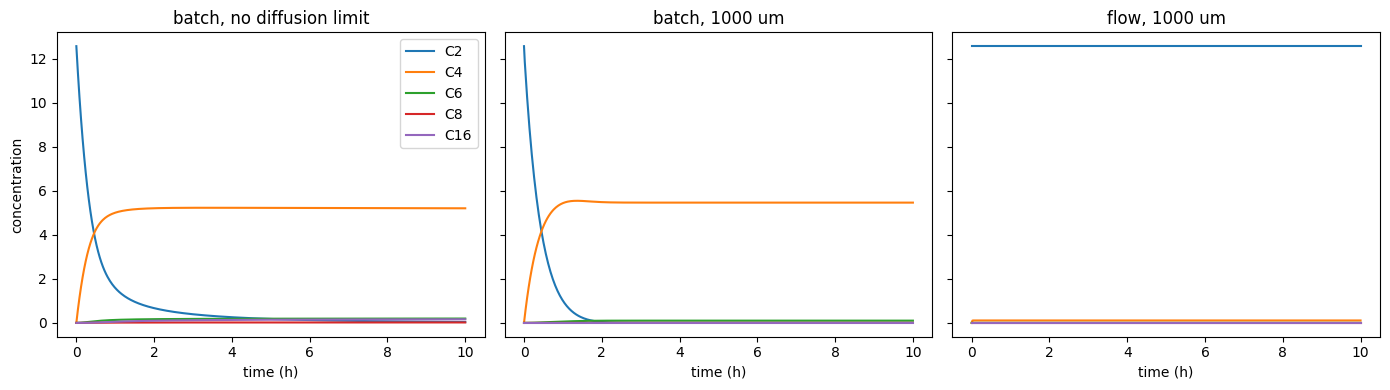

In [2]:
# C(t), pore
fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (case, (dist, ts)) in zip(axs, runs.items()):
    t = ts.index / 3600
    for sp in ('C2', 'C4', 'C6', 'C8', 'C16'):
        ax.plot(t, ts[sp], label=sp)
    ax.set_title(case); ax.set_xlabel('time (h)')
axs[0].set_ylabel('concentration'); axs[0].legend()
plt.tight_layout()

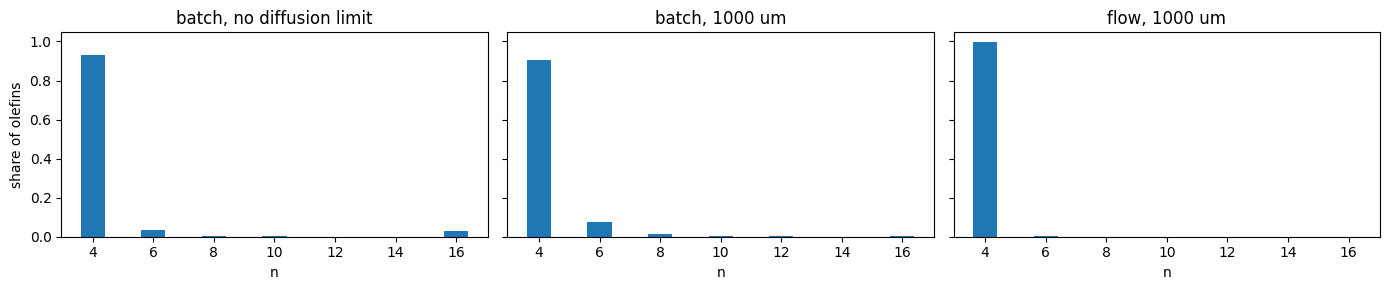

In [3]:
# product distribution after 10 h
fig, axs = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
for ax, (case, (dist, ts)) in zip(axs, runs.items()):
    d = dist.dropna(subset=['probability'])
    ax.bar(d.n, d.probability); ax.set_title(case); ax.set_xlabel('n')
axs[0].set_ylabel('share of olefins')
plt.tight_layout()